# Wilson Score vs. Bayesian Credible Interval

This notebook explores the estimation of a binomial success parameter $p$ given $k$ successes in $n$ independent trials ($n = 10, k = 2$).

We compare:
1. **Frequentist Wilson Score Interval**
2. **Conjugate Bayesian Analytical Posterior** (Uniform $\text{Beta}(1, 1)$ prior $\to \text{Beta}(3, 9)$ posterior)
3. **Markov Chain Monte Carlo (MCMC)** via Random Walk Metropolis-Hastings

We also check each method by simulation:
* **Frequentist:** fix $p_{\text{true}}$, simulate many datasets, and confirm that about 95% of the Wilson intervals contain $p_{\text{true}}$.
* **Bayesian:** fix the observed data, simulate $(p, k)$ pairs from the generative model, keep those with $k = 2$, and confirm that the kept $p$ values follow $\text{Beta}(3, 9)$.

---

## Frequentist Estimation: Wilson Score Interval

In [1]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

# Problem parameters
n = 10
k = 2
p_hat = k / n
alpha = 0.05
z = stats.norm.ppf(1 - alpha / 2)

# 1. Wilson Score Interval
denominator = 1 + (z**2) / n
center_adj = (p_hat + (z**2) / (2 * n)) / denominator
margin = (z / denominator) * np.sqrt((p_hat * (1 - p_hat) / n) + (z**2 / (4 * n**2)))
wilson_ci = (center_adj - margin, center_adj + margin)

print(f"Wilson 95% Confidence Interval : [{wilson_ci[0]:.4f}, {wilson_ci[1]:.4f}]")

Wilson 95% Confidence Interval : [0.0567, 0.5098]


### Coverage of the Wilson Interval

A 95% confidence interval makes a claim about the *procedure*, not about any single interval: if we repeatedly draw new data from $\text{Binomial}(n, p_{\text{true}})$ and build a Wilson interval from each dataset, about 95% of those intervals should contain the **true** parameter $p_{\text{true}}$.

(The estimate $\hat{p} = k/n$ always lies inside its own Wilson interval, so checking whether each interval contains its own estimate tells us nothing. The useful check is whether each interval contains $p_{\text{true}}$.)

#### Binomial Sampling Distribution
In the frequentist view, the parameter $p = p_{\text{true}}$ is a **fixed constant**, and the data $K$ is the random quantity. Each repeated experiment draws

$$K \sim \text{Binomial}(n, p_{\text{true}})$$

with probability mass function

$$P(K = k \mid n, p_{\text{true}}) = \binom{n}{k} p_{\text{true}}^k (1 - p_{\text{true}})^{n - k}, \quad k \in \{0, 1, \dots, n\}$$

where:
* **Expected value:** $\mathbb{E}[K] = n p_{\text{true}}$
* **Variance:** $\text{Var}(K) = n p_{\text{true}} (1 - p_{\text{true}})$

The parameter stays fixed and the interval moves from one experiment to the next. Because there are only $n + 1$ possible values of $K$, the exact coverage is a finite sum:

$$\text{Coverage}(p_{\text{true}}) = \sum_{k=0}^{n} \mathbb{1}\left[p_{\text{true}} \in \text{CI}(k)\right] \binom{n}{k} p_{\text{true}}^k (1 - p_{\text{true}})^{n - k}$$

Below we set $p_{\text{true}} = 0.2$ and keep $n = 10$:
- **Left:** 100 simulated datasets, each with its own Wilson interval. Intervals that miss $p_{\text{true}}$ are shown in red.
- **Right:** The running fraction of intervals that cover $p_{\text{true}}$ over 10,000 simulated datasets, compared with the exact coverage.

Because $k$ can only take the values $0, 1, \dots, n$, the exact coverage for small $n$ is not exactly 95%. It moves up and down around the nominal level as $p_{\text{true}}$ changes.

Empirical coverage (10,000 sims): 0.9673
Exact coverage at p_true = 0.2  : 0.9672
Nominal coverage                  : 0.9500


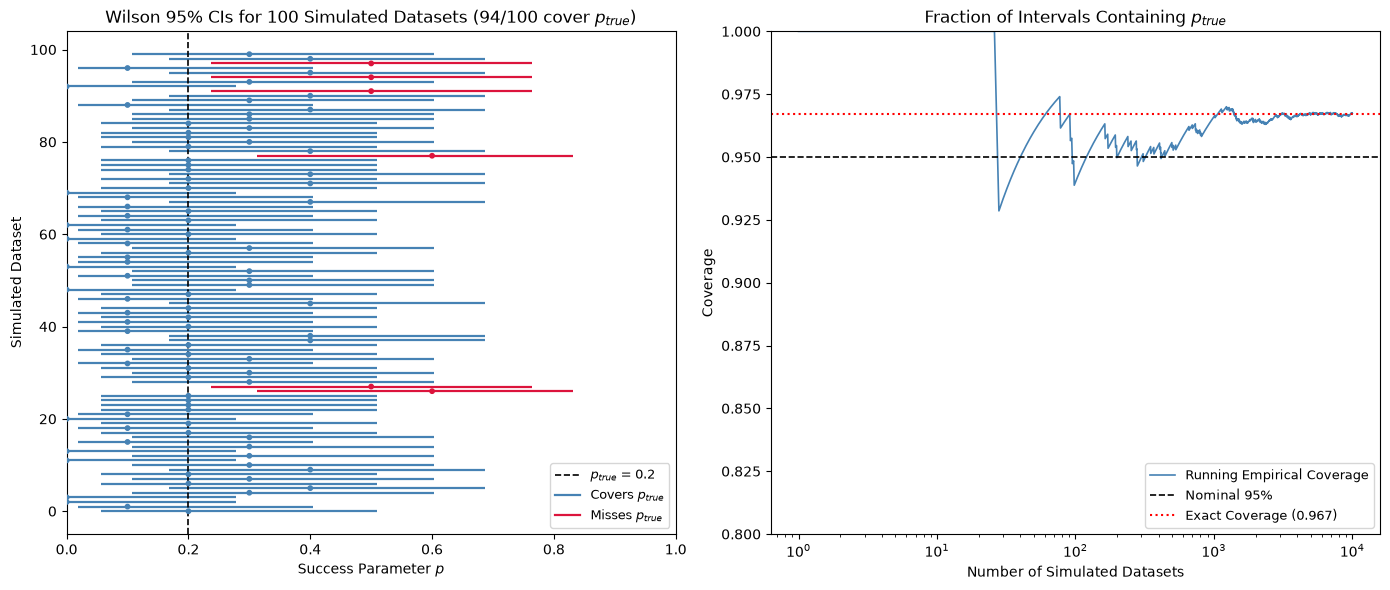

In [2]:
def wilson_interval(k, n, z):
    """Vectorized Wilson score interval for k successes in n trials."""
    p_hat = np.asarray(k) / n
    denominator = 1 + z**2 / n
    center = (p_hat + z**2 / (2 * n)) / denominator
    half_width = (z / denominator) * np.sqrt(p_hat * (1 - p_hat) / n + z**2 / (4 * n**2))
    return center - half_width, center + half_width

p_true = 0.2
rng = np.random.default_rng(0)

# Simulate many binomial datasets and build a Wilson interval for each
n_sims = 10_000
k_sims = rng.binomial(n, p_true, size=n_sims)
lower_sims, upper_sims = wilson_interval(k_sims, n, z)
covered = (lower_sims <= p_true) & (p_true <= upper_sims)

# Exact coverage: sum the Binomial pmf over every k whose interval contains p_true
k_all = np.arange(n + 1)
lower_all, upper_all = wilson_interval(k_all, n, z)
exact_coverage = stats.binom.pmf(k_all, n, p_true)[(lower_all <= p_true) & (p_true <= upper_all)].sum()

print(f"Empirical coverage ({n_sims:,} sims): {covered.mean():.4f}")
print(f"Exact coverage at p_true = {p_true}  : {exact_coverage:.4f}")
print(f"Nominal coverage                  : {1 - alpha:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Left: first 100 intervals
n_show = 100
idx = np.arange(n_show)
colors = np.where(covered[:n_show], "steelblue", "crimson")
axes[0].hlines(idx, lower_sims[:n_show], upper_sims[:n_show], colors=colors, lw=1.6)
axes[0].scatter(k_sims[:n_show] / n, idx, color=colors, s=10, zorder=3)
axes[0].axvline(p_true, color="black", linestyle="--", lw=1.2, label=f"$p_{{true}}$ = {p_true}")
axes[0].set_title(f"Wilson 95% CIs for {n_show} Simulated Datasets "
                  f"({covered[:n_show].sum()}/{n_show} cover $p_{{true}}$)")
axes[0].set_xlabel("Success Parameter $p$")
axes[0].set_ylabel("Simulated Dataset")
axes[0].set_xlim(0, 1)
axes[0].plot([], [], color="steelblue", lw=1.6, label="Covers $p_{true}$")
axes[0].plot([], [], color="crimson", lw=1.6, label="Misses $p_{true}$")
axes[0].legend(frameon=True, fontsize=9, loc="lower right")

# Right: running coverage converging to the exact value
running_coverage = np.cumsum(covered) / np.arange(1, n_sims + 1)
axes[1].plot(np.arange(1, n_sims + 1), running_coverage, color="steelblue", lw=1.2, label="Running Empirical Coverage")
axes[1].axhline(1 - alpha, color="black", linestyle="--", lw=1.2, label="Nominal 95%")
axes[1].axhline(exact_coverage, color="red", linestyle=":", lw=1.5, label=f"Exact Coverage ({exact_coverage:.3f})")
axes[1].set_xscale("log")
axes[1].set_ylim(0.8, 1.0)
axes[1].set_title("Fraction of Intervals Containing $p_{true}$")
axes[1].set_xlabel("Number of Simulated Datasets")
axes[1].set_ylabel("Coverage")
axes[1].legend(frameon=True, fontsize=9, loc="lower right")

plt.tight_layout()
plt.show()

#### Why Exact Coverage Differs from Nominal Coverage

Two effects separate the exact coverage (0.967 here) from the nominal 95%:

1. **Discreteness.** $K$ takes only $n + 1 = 11$ values, so there are only 11 possible intervals. At $p_{\text{true}} = 0.2$, the intervals for $k = 0, \dots, 4$ contain $p_{\text{true}}$ and those for $k \geq 5$ do not (the $k = 5$ interval starts at 0.237). Coverage is therefore $P(K \leq 4) \approx 0.967$. The next achievable value down is $P(K \leq 3) \approx 0.879$; nothing in between is possible. As $p_{\text{true}}$ moves, it crosses interval endpoints one at a time, so coverage jumps up and down around 95% in a sawtooth pattern.
2. **Normal approximation.** The Wilson interval inverts a score test that treats $(\hat{p} - p)/\sqrt{p(1-p)/n}$ as standard normal, which is where $z = 1.96$ comes from. That is exact only as $n \to \infty$; for small $n$ the binomial is skewed, especially near 0 or 1.

No interval built without randomization can have exactly 95% coverage at every $p_{\text{true}}$ when the data are discrete. Wilson stays close to 95%, sometimes above and sometimes below. Clopper–Pearson guarantees at least 95% at the cost of being conservative. The gap shrinks as $n$ grows. The small difference between empirical and exact coverage is Monte Carlo noise (standard error $\approx \sqrt{0.967 \cdot 0.033 / 10{,}000} \approx 0.002$).

---

## Bayesian Estimation: Conjugate Beta Posterior

In the Bayesian view, the observed data $(n, k) = (10, 2)$ is **fixed**, and uncertainty about $p$ is described by a probability distribution. By Bayes' Theorem:

$$P(p \mid k) = \frac{P(k \mid p) \, P(p)}{P(k)} \propto P(k \mid p) \, P(p)$$

### 1. Likelihood (Binomial Model)
Given $p$, the probability of observing $k = 2$ successes in $n = 10$ independent trials is:

$$P(k \mid p) = \binom{n}{k} p^k (1 - p)^{n - k} \propto p^k (1 - p)^{n - k}$$

### 2. Prior (Beta Model)
We place a flat (uniform) prior on $p \in [0, 1]$, which is a $\text{Beta}(\alpha_0, \beta_0)$ distribution with $\alpha_0 = \beta_0 = 1$:

$$P(p) = \frac{1}{\text{B}(\alpha_0, \beta_0)} p^{\alpha_0 - 1} (1 - p)^{\beta_0 - 1} \propto p^{\alpha_0 - 1} (1 - p)^{\beta_0 - 1}$$

### 3. Conjugate Update
Multiplying the likelihood kernel by the prior kernel:

$$P(p \mid k) \propto \left[ p^k (1 - p)^{n - k} \right] \times \left[ p^{\alpha_0 - 1} (1 - p)^{\beta_0 - 1} \right] = p^{(\alpha_0 + k) - 1} (1 - p)^{(\beta_0 + n - k) - 1}$$

This has the form of another Beta distribution (**Beta-Binomial conjugacy**):

$$p \mid k \sim \text{Beta}(\alpha_{\text{post}}, \beta_{\text{post}}), \qquad \alpha_{\text{post}} = \alpha_0 + k = 3, \qquad \beta_{\text{post}} = \beta_0 + n - k = 9$$

So the posterior is exactly $\text{Beta}(3, 9)$, with density

$$f(p \mid k = 2, n = 10) = \frac{\Gamma(12)}{\Gamma(3)\,\Gamma(9)} p^2 (1 - p)^8 = 165 \, p^2 (1 - p)^8$$

We report its 95% equal-tailed credible interval, which runs between the 2.5% and 97.5% quantiles of the posterior.

In [3]:
# 2. Conjugate Bayesian Posterior (Beta(1,1) prior)
alpha_prior, beta_prior = 1.0, 1.0
alpha_post = alpha_prior + k
beta_post = beta_prior + n - k
analytical_ci = stats.beta.interval(1 - alpha, alpha_post, beta_post)

print(f"Bayesian 95% Credible Interval: [{analytical_ci[0]:.4f}, {analytical_ci[1]:.4f}]")

Bayesian 95% Credible Interval: [0.0602, 0.5178]


### Bayesian Generative Simulation

We can check the posterior without any algebra by simulating the generative model directly:

1. Draw a candidate parameter from the prior: $p \sim \text{Beta}(1, 1)$.
2. Generate synthetic data from it: $k_{\text{sim}} \sim \text{Binomial}(n, p)$.
3. Keep $p$ only if $k_{\text{sim}}$ equals the observed $k = 2$.

This is **rejection sampling**: the kept draws are exact samples from $P(p \mid k = 2)$. If the analysis is right, their histogram should match $\text{Beta}(3, 9)$, and about 95% of them should fall inside the 95% credible interval.

This is the mirror image of the coverage simulation above. There, $p$ was fixed and the data varied. Here, the data is fixed and $p$ varies.

Forward joint draws           : 1,000,000
Accepted draws with k_sim = 2 : 90,952 (expected 90,909, since P(k) = 1/(n+1) under a flat prior)
Mass inside 95% credible interval [0.0602, 0.5178]: 0.9499


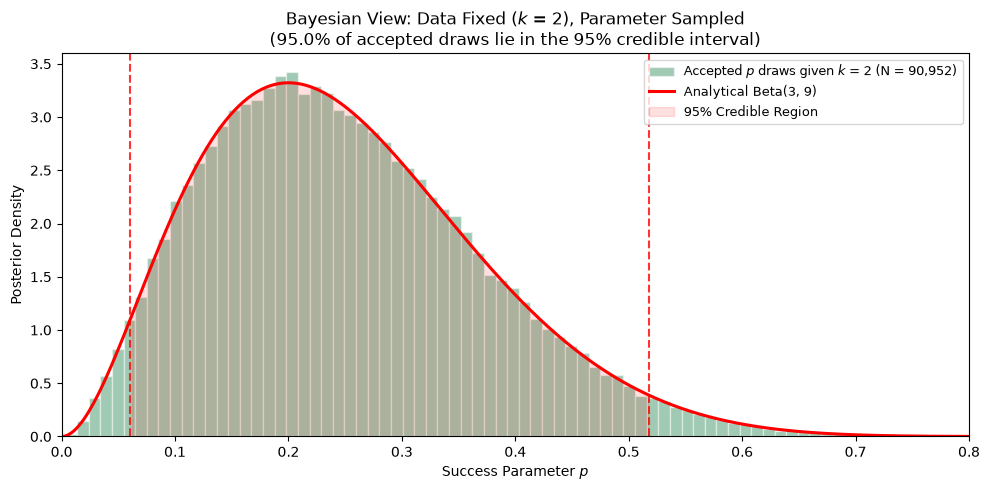

In [4]:
rng = np.random.default_rng(1)
n_forward = 1_000_000

# 1. Forward generative sampling: p ~ Beta(1, 1), k_sim ~ Binomial(n, p)
p_prior_draws = rng.beta(alpha_prior, beta_prior, size=n_forward)
k_forward = rng.binomial(n, p_prior_draws)

# 2. Condition on the observed data by keeping only draws with k_sim == k
p_posterior_draws = p_prior_draws[k_forward == k]

# 3. Fraction of posterior draws inside the analytical 95% credible interval
in_cri = (analytical_ci[0] <= p_posterior_draws) & (p_posterior_draws <= analytical_ci[1])
empirical_mass = in_cri.mean()

print(f"Forward joint draws           : {n_forward:,}")
print(f"Accepted draws with k_sim = {k} : {len(p_posterior_draws):,} "
      f"(expected {n_forward / (n + 1):,.0f}, since P(k) = 1/(n+1) under a flat prior)")
print(f"Mass inside 95% credible interval [{analytical_ci[0]:.4f}, {analytical_ci[1]:.4f}]: {empirical_mass:.4f}")

x_grid = np.linspace(0, 1, 500)
pdf_analytical = stats.beta.pdf(x_grid, alpha_post, beta_post)
in_grid = (x_grid >= analytical_ci[0]) & (x_grid <= analytical_ci[1])

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(p_posterior_draws, bins=80, density=True, alpha=0.45, color="seagreen", edgecolor="white",
        label=f"Accepted $p$ draws given $k$ = {k} (N = {len(p_posterior_draws):,})")
ax.plot(x_grid, pdf_analytical, "r-", lw=2.2, label="Analytical Beta(3, 9)")
ax.fill_between(x_grid[in_grid], pdf_analytical[in_grid], color="red", alpha=0.12, label="95% Credible Region")
ax.axvline(analytical_ci[0], color="red", linestyle="--", alpha=0.8)
ax.axvline(analytical_ci[1], color="red", linestyle="--", alpha=0.8)
ax.set_title(f"Bayesian View: Data Fixed ($k$ = {k}), Parameter Sampled\n"
             f"({empirical_mass:.1%} of accepted draws lie in the 95% credible interval)")
ax.set_xlabel("Success Parameter $p$")
ax.set_ylabel("Posterior Density")
ax.set_xlim(0, 0.8)
ax.legend(frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

---

## Markov Chain Monte Carlo (MCMC) Posterior Estimation

### 1. Bayesian Formulation and Target Distribution

By Bayes' Theorem, the posterior density of the binomial rate parameter $p \in (0, 1)$ given observed data $\mathcal{D} = (n, k)$ is:

$$P(p \mid k, n) = \frac{P(k \mid n, p) \, P(p)}{P(k \mid n)} = \frac{\mathcal{L}(p) \, \pi(p)}{\int_0^1 \mathcal{L}(p') \, \pi(p') \, dp'}$$

Where:
- **Likelihood**: $\mathcal{L}(p) = \binom{n}{k} p^k (1 - p)^{n - k} \propto p^k (1 - p)^{n - k}$
- **Prior**: $\pi(p) = \frac{p^{\alpha_0 - 1} (1 - p)^{\beta_0 - 1}}{\text{B}(\alpha_0, \beta_0)}$. Under a flat $\text{Beta}(1, 1)$ prior, $\pi(p) = 1$ for $p \in [0, 1]$.
- **Evidence (Marginal Likelihood)**: $\int_0^1 \mathcal{L}(p') \pi(p') dp'$, which acts as a normalizing constant independent of $p$.

Because the marginal likelihood does not depend on $p$, the unnormalized target density is:

$$\tilde{P}(p \mid k, n) \propto p^k (1 - p)^{n - k} \, p^{\alpha_0 - 1} (1 - p)^{\beta_0 - 1} = p^{k + \alpha_0 - 1} (1 - p)^{n - k + \beta_0 - 1}$$

To avoid underflow when evaluating probabilities, we compute the unnormalized **log-posterior**:

$$\ln \tilde{P}(p \mid k, n) = (k + \alpha_0 - 1) \ln p + (n - k + \beta_0 - 1) \ln(1 - p)$$

### 2. The Metropolis-Hastings Algorithm

Metropolis-Hastings constructs an ergodic Markov chain whose stationary distribution matches $P(p \mid k, n)$. Given state $p_t$:

1. **Proposal**: Sample candidate $p^* \sim q(p^* \mid p_t)$ from a symmetric Gaussian random walk:
   $$p^* = p_t + \epsilon, \quad \epsilon \sim \mathcal{N}(0, \sigma_{\text{prop}}^2)$$
2. **Acceptance Probability**: Compute ratio $\alpha(p_t, p^*)$:
   $$\alpha(p_t, p^*) = \min\left(1, \frac{\tilde{P}(p^*) \, q(p_t \mid p^*)}{\tilde{P}(p_t) \, q(p^* \mid p_t)}\right)$$
   Because $q$ is symmetric ($q(p^* \mid p_t) = q(p_t \mid p^*)$), the proposal terms cancel out, leaving the standard Metropolis ratio:
   $$\alpha(p_t, p^*) = \min\left(1, \frac{\tilde{P}(p^*)}{\tilde{P}(p_t)}\right) = \min\left(1, \exp\left[\ln \tilde{P}(p^*) - \ln \tilde{P}(p_t)\right]\right)$$
   If $p^* \notin (0, 1)$, $\tilde{P}(p^*) = 0$ (log-posterior is $-\infty$), so $\alpha(p_t, p^*) = 0$.
3. **Update**: Draw $u \sim \text{Uniform}(0, 1)$. If $u \le \alpha(p_t, p^*)$, set $p_{t+1} = p^*$; otherwise, set $p_{t+1} = p_t$.

In [5]:
def log_posterior(p, n, k, a=1.0, b=1.0):
    """Log unnormalized posterior for Binomial likelihood + Beta(a, b) prior."""
    if p <= 0.0 or p >= 1.0:
        return -np.inf
    return (k + a - 1.0) * np.log(p) + (n - k + b - 1.0) * np.log(1.0 - p)

def run_metropolis_hastings(n_samples=60_000, burn_in=10_000, proposal_sd=0.08, seed=42):
    rng = np.random.default_rng(seed)
    samples = np.empty(n_samples)
    
    current_p = 0.5
    current_lp = log_posterior(current_p, n, k, alpha_prior, beta_prior)
    accepted = 0
    
    for step in range(n_samples + burn_in):
        candidate = current_p + rng.normal(0.0, proposal_sd)
        candidate_lp = log_posterior(candidate, n, k, alpha_prior, beta_prior)
        
        # Log-acceptance threshold
        log_alpha = candidate_lp - current_lp
        if np.log(rng.uniform(0.0, 1.0)) < log_alpha:
            current_p = candidate
            current_lp = candidate_lp
            if step >= burn_in:
                accepted += 1
                
        if step >= burn_in:
            samples[step - burn_in] = current_p
            
    acceptance_rate = accepted / n_samples
    return samples, acceptance_rate

# Sample the posterior
mcmc_samples, acc_rate = run_metropolis_hastings()

# Empirical statistics
mcmc_mean = np.mean(mcmc_samples)
mcmc_var = np.var(mcmc_samples, ddof=1)
mcmc_ci = np.percentile(mcmc_samples, [2.5, 97.5])

# Analytical statistics for Beta(3, 9)
analytical_mean = alpha_post / (alpha_post + beta_post)
analytical_var = (alpha_post * beta_post) / ((alpha_post + beta_post)**2 * (alpha_post + beta_post + 1))

print(f"MCMC Acceptance Rate : {acc_rate:.3f}")
print("-" * 60)
print(f"{'Metric':<24}{'Analytical Beta(3,9)':<20}{'MCMC Estimate':<16}")
print("-" * 60)
print(f"{'Mean':<24}{analytical_mean:<20.5f}{mcmc_mean:<16.5f}")
print(f"{'Variance':<24}{analytical_var:<20.5f}{mcmc_var:<16.5f}")
print(f"{'95% Equal-Tailed CI':<24}[{analytical_ci[0]:.4f}, {analytical_ci[1]:.4f}]    [{mcmc_ci[0]:.4f}, {mcmc_ci[1]:.4f}]")
print("-" * 60)

MCMC Acceptance Rate : 0.791
------------------------------------------------------------
Metric                  Analytical Beta(3,9)MCMC Estimate   
------------------------------------------------------------
Mean                    0.25000             0.24794         
Variance                0.01442             0.01441         
95% Equal-Tailed CI     [0.0602, 0.5178]    [0.0582, 0.5165]
------------------------------------------------------------


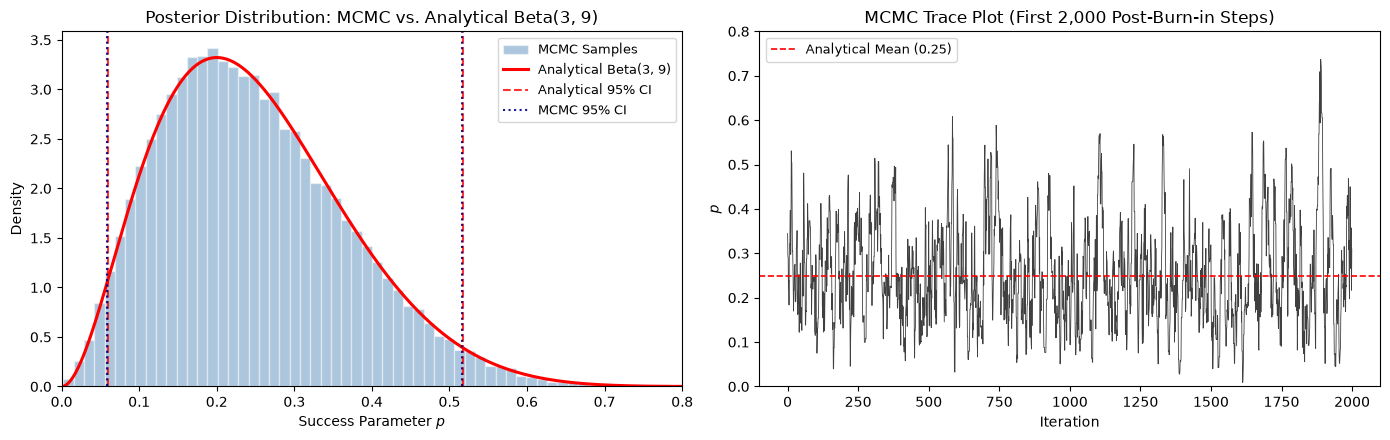

In [6]:
# Visual validation: Empirical histogram vs. Analytical Beta density
x_grid = np.linspace(0, 1, 500)
pdf_analytical = stats.beta.pdf(x_grid, alpha_post, beta_post)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Posterior histogram vs. theoretical PDF
axes[0].hist(mcmc_samples, bins=60, density=True, alpha=0.45, color="steelblue", edgecolor="white", label="MCMC Samples")
axes[0].plot(x_grid, pdf_analytical, "r-", lw=2.2, label="Analytical Beta(3, 9)")
axes[0].axvline(analytical_ci[0], color="red", linestyle="--", alpha=0.8, label="Analytical 95% CI")
axes[0].axvline(analytical_ci[1], color="red", linestyle="--", alpha=0.8)
axes[0].axvline(mcmc_ci[0], color="navy", linestyle=":", alpha=0.9, label="MCMC 95% CI")
axes[0].axvline(mcmc_ci[1], color="navy", linestyle=":", alpha=0.9)
axes[0].set_title("Posterior Distribution: MCMC vs. Analytical Beta(3, 9)")
axes[0].set_xlabel("Success Parameter $p$")
axes[0].set_ylabel("Density")
axes[0].set_xlim(0, 0.8)
axes[0].legend(frameon=True, fontsize=9)

# Trace plot of first 2,000 post-burn-in iterations
axes[1].plot(mcmc_samples[:2000], lw=0.6, color="black", alpha=0.75)
axes[1].axhline(analytical_mean, color="red", linestyle="--", lw=1.2, label=f"Analytical Mean ({analytical_mean:.2f})")
axes[1].set_title("MCMC Trace Plot (First 2,000 Post-Burn-in Steps)")
axes[1].set_xlabel("Iteration")
axes[1].set_ylabel("$p$")
axes[1].set_ylim(0, 0.8)
axes[1].legend(frameon=True, fontsize=9)

plt.tight_layout()
plt.show()